# Empleo en empresas de baja productividad

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "empleo-empresas-baja-productividad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Empleo en empresas de baja productividad"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de las personas ocupadas de la economía empresarial no financiera"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de las **personas ocupadas** de la economía empresarial no financiera (industria, construcción, comercio, transporte, hostelería, información y comunicaciones, actividades inmobiliarias, profesionales y administrativas) que trabajan en **grupos de empresas de baja productividad**: los grupos (una actividad económica a dos dígitos de la NACE y una clase de tamaño: de 0 a 9, de 10 a 19, de 20 a 49, de 50 a 249 y de 250 o más personas ocupadas) cuyo valor añadido por persona ocupada no llega a la **mitad del de la UE-27** del mismo año, con los precios ajustados por la capacidad de compra de cada país. Se calcula para España y para el conjunto de la UE-27.

**Por qué una serie y no una dispersión.** Antes se comparaba con la productividad por hora de cada país, pero los dos ejes no eran independientes: más empleo en empresas poco productivas baja, por definición, la productividad media. La serie muestra cómo ha cambiado el peso de esas empresas en España frente a la UE-27 (por indicación humana del 2026-10-18).

**Cálculo propio.** Eurostat no publica la productividad de cada empresa, sino la de los grupos de empresas de una misma actividad y tamaño: el indicador se calcula a la vista en este notebook y requiere la aprobación de la revisión humana (METODOLOGIA §2.3).

**Limitaciones.**
- Es una aproximación por grupos y no por empresa: una empresa muy productiva en un grupo poco productivo cuenta como poco productiva, y al revés.
- El umbral es la mitad de la productividad media de la UE-27 en el conjunto de la economía empresarial no financiera: depende de la composición por actividades (una actividad de poca productividad, como la hostelería, pesa más en unos países que en otros).
- Algunas celdas (actividad, tamaño) no se publican por secreto estadístico: se excluyen del numerador y del denominador y se cuentan en las notas.
- **Ruptura de serie en 2021:** Eurostat cambió el reglamento de las estadísticas estructurales de empresas (nuevas tablas y, en algunos países, otra unidad estadística). Los datos de 2008 a 2020 y los de 2021 en adelante salen de tablas distintas; la cobertura de actividades es la misma en los dos tramos.
- No hay dato de la OCDE, EE. UU. ni Canadá: las estadísticas estructurales de empresas son de Eurostat.

## 2. Descarga

- **Eurostat, estadísticas estructurales de empresas desde 2021** (`sbs_sc_ovw`): para España y la UE-27, cada división de la NACE Rev. 2 (dos dígitos) y cada clase de tamaño (`0-9`, `10-19`, `20-49`, `50-249` y `GE250` personas ocupadas), la productividad aparente del trabajo (`LABPRY_TEUR`, miles de euros por persona ocupada) y las personas ocupadas (`EMP_NR`).
- **Eurostat, estadísticas estructurales de empresas de 2008 a 2020** (`sbs_sc_ind_r2` industria, `sbs_sc_con_r2` construcción, `sbs_sc_dt_r2` comercio y `sbs_sc_1b_se_r2` servicios): el valor añadido a coste de los factores (`V12150`, millones de euros) y las personas ocupadas (`V16110`) por división y clase de tamaño. En comercio y servicios, la clase de 0 a 9 personas se publica partida (`0_1` y `2-9`) y se suma.
- **Eurostat, niveles de precios** (`prc_ppp_ind`): índice de nivel de precios del PIB de España (`PLI_EU27_2020`, UE-27 = 100), con el que los euros se convierten en estándares de poder adquisitivo (PPS) de la UE-27.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import time
from datetime import date

import numpy as np
import pandas as pd
import requests

from lib import estilos, eurostat
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

HOY = date.today().isoformat()
GEOS = {"ES": "espana", "EU27_2020": "ue27"}
TAMANOS = ["0-9", "10-19", "20-49", "50-249", "GE250"]  # no se solapan
# Economía empresarial no financiera: divisiones de B a N sin K (actividades financieras), las mismas en los dos tramos
PATRON_DIVISION = r"^[B-JLMN]\d{2}$"
SBS_NUEVA, DESDE_NUEVA = "sbs_sc_ovw", 2021
SBS_ANTIGUAS = ["sbs_sc_ind_r2", "sbs_sc_con_r2", "sbs_sc_dt_r2", "sbs_sc_1b_se_r2"]
DESDE_ANTIGUA, HASTA_ANTIGUA = 2008, 2020  # NACE Rev. 2 desde 2008


def aplanar_jsonstat(js):
    """Dataset JSON-stat (todas las dimensiones) -> DataFrame con una columna por dimensión y `valor`."""
    ids, tamanos = js["id"], js["size"]
    cats = {d: list(js["dimension"][d]["category"]["index"]) for d in ids}
    valores = js.get("value", {})
    if isinstance(valores, list):
        valores = {str(i): v for i, v in enumerate(valores) if v is not None}
    if not valores:
        return pd.DataFrame(columns=[*ids, "valor"])
    idx = np.array([int(k) for k in valores])
    pos = np.unravel_index(idx, tamanos)
    datos = {d: np.array(cats[d])[p] for d, p in zip(ids, pos)}
    datos["valor"] = np.array([float(v) for v in valores.values()])
    return pd.DataFrame(datos)


def descargar(dataset, dim_indicador, indicador, geo, desde, sesion, hasta=None):
    """Todas las divisiones y clases de tamaño de un indicador y un territorio."""
    params = [("format", "JSON"), ("lang", "EN"), ("sinceTimePeriod", str(desde)),
              (dim_indicador, indicador), ("geo", geo), ("freq", "A")]
    if hasta:
        params.append(("untilTimePeriod", str(hasta)))
    df = aplanar_jsonstat(eurostat._pedir(dataset, params, sesion, reintentos=2))
    df = df.rename(columns={dim_indicador: "indicador"})
    df["dataset"] = dataset
    return df


sesion = requests.Session()
trozos = []
for geo in GEOS:
    for ind in ("LABPRY_TEUR", "EMP_NR"):
        trozos.append(descargar(SBS_NUEVA, "indic_sbs", ind, geo, DESDE_NUEVA, sesion))
        time.sleep(0.2)  # cortesía con el servidor
    for ds in SBS_ANTIGUAS:
        for ind in ("V12150", "V16110"):
            trozos.append(descargar(ds, "indic_sb", ind, geo, DESDE_ANTIGUA, sesion, hasta=HASTA_ANTIGUA))
            time.sleep(0.2)
sbs = pd.concat(trozos, ignore_index=True)
sbs["serie"] = sbs["geo"].map(GEOS)
sbs["anio"] = sbs["time"].astype(int)
print(sbs.groupby(["dataset", "serie"])["anio"].agg(["min", "max", "count"]))

# Índice de nivel de precios del PIB de España (UE-27 = 100) para pasar de euros a PPS de la UE-27
pli, _ = eurostat.get(
    "prc_ppp_ind", {"freq": "A", "na_item": "PLI_EU27_2020", "ppp_cat": "GDP"}, geos={"ES": "espana"}, desde=DESDE_ANTIGUA,
)

                         min   max  count
dataset         serie                    
sbs_sc_1b_se_r2 espana  2008  2020  17252
                ue27    2011  2020  12226
sbs_sc_con_r2   espana  2008  2020   1788
                ue27    2011  2020   1382
sbs_sc_dt_r2    espana  2008  2020   4194
                ue27    2011  2020   3251
sbs_sc_ind_r2   espana  2008  2020  19594
                ue27    2011  2020  13853
sbs_sc_ovw      espana  2021  2024  15582
                ue27    2021  2024  16075


## 3. Transformación

**Cálculo (propio, a la vista):**

1. **Grupos:** cada (división de la NACE a dos dígitos de B a N sin K, clase de tamaño). En el tramo de 2008 a 2020, la clase de 0 a 9 personas de comercio y servicios es la suma de `0_1` y `2-9` (solo si las dos están publicadas). Valor añadido: en el tramo nuevo, productividad aparente × personas ocupadas; en el antiguo, el publicado.
2. Se excluyen del numerador y del denominador los grupos sin valor añadido o sin personas ocupadas publicados (secreto estadístico).
3. La productividad de cada grupo de España se convierte de euros a PPS de la UE-27 dividiendo por el índice de nivel de precios del PIB del año (UE-27 = 100); la de la UE-27 ya está en PPS de la UE-27.
4. **Umbral:** la mitad de la productividad de la UE-27 en el conjunto de los grupos con dato de la UE-27 (suma del valor añadido entre suma de las personas ocupadas) del mismo año.
5. **Indicador** = personas ocupadas de los grupos por debajo del umbral / personas ocupadas de todos los grupos con dato × 100, para España y para la UE-27.
6. **Contraste para las notas (España, último año):** la cobertura (personas ocupadas de los grupos con dato frente al total de las divisiones).

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


def grupos_con_valor_anadido(sbs):
    """Una fila por (serie, año, división, tamaño) con valor añadido (millones de euros) y personas ocupadas."""
    s = sbs[sbs["nace_r2"].str.fullmatch(PATRON_DIVISION)]
    t = s.pivot_table(index=["serie", "anio", "nace_r2", "size_emp"], columns="indicador", values="valor", aggfunc="first").reset_index()
    nueva = t[t["anio"] >= DESDE_NUEVA].copy()
    nueva["va"] = nueva["LABPRY_TEUR"] * nueva["EMP_NR"] / 1000
    nueva["emp"] = nueva["EMP_NR"]
    antigua = t[t["anio"] <= HASTA_ANTIGUA].rename(columns={"V12150": "va", "V16110": "emp"})
    # Comercio y servicios publican 0_1 y 2-9: se suman en 0-9 solo si están las dos y no hay 0-9
    partes = antigua[antigua["size_emp"].isin(["0_1", "2-9"])]
    suma = partes.groupby(["serie", "anio", "nace_r2"]).agg(va=("va", lambda v: v.sum(min_count=2)), emp=("emp", lambda v: v.sum(min_count=2)), n=("size_emp", "nunique"))
    suma = suma[suma["n"] == 2].drop(columns="n").reset_index().assign(size_emp="0-9")
    con_09 = set(map(tuple, antigua.loc[antigua["size_emp"] == "0-9", ["serie", "anio", "nace_r2"]].values))
    suma = suma[[t not in con_09 for t in map(tuple, suma[["serie", "anio", "nace_r2"]].values)]]
    antigua = pd.concat([antigua[antigua["size_emp"].isin(TAMANOS)], suma], ignore_index=True)
    cols = ["serie", "anio", "nace_r2", "size_emp", "va", "emp"]
    g = pd.concat([nueva[nueva["size_emp"].isin(TAMANOS)][cols], antigua[cols]], ignore_index=True)
    return g


grupos = grupos_con_valor_anadido(sbs)
posibles = grupos.copy()
grupos = grupos.dropna(subset=["va", "emp"])
grupos = grupos[grupos["emp"] > 0]
nivel_precios = pli.set_index("periodo")["valor"]

filas = []
for anio in sorted(grupos["anio"].unique()):
    ue = grupos[(grupos["serie"] == "ue27") & (grupos["anio"] == anio)]
    if ue.empty:
        continue
    umbral = 0.5 * ue["va"].sum() / ue["emp"].sum()  # millones de PPS por persona ocupada
    for serie, g in grupos[grupos["anio"] == anio].groupby("serie"):
        precio = 100.0 if serie == "ue27" else nivel_precios.get(anio)
        if precio is None or np.isnan(precio):
            continue
        pps = g["va"] / g["emp"] * 100 / precio
        bajo = pps < umbral
        filas.append({
            "serie": serie, "periodo": int(anio), "valor": g.loc[bajo, "emp"].sum() / g["emp"].sum() * 100,
            "grupos": len(g), "posibles": int(((posibles["serie"] == serie) & (posibles["anio"] == anio)).sum()),
            "umbral_miles_pps": umbral * 1000,
        })
calculo = pd.DataFrame(filas)
print(calculo.round(1).to_string(index=False))

df = calculo[["serie", "periodo", "valor"]]
vacias = pd.DataFrame({"serie": ["ocde", "eeuu", "canada"], "periodo": [DESDE] * 3, "valor": [float("nan")] * 3})
df = pd.concat([df, vacias], ignore_index=True)

fuente = (f"{SBS_NUEVA} (LABPRY_TEUR, EMP_NR) desde {DESDE_NUEVA}; {', '.join(SBS_ANTIGUAS)} (V12150, V16110) de "
          f"{DESDE_ANTIGUA} a {HASTA_ANTIGUA}; prc_ppp_ind (PLI_EU27_2020, GDP): cálculo propio")
fuentes = [
    FuenteMeta("espana", eurostat.ORGANISMO, fuente, eurostat.URL_DATABROWSER.format(dataset=SBS_NUEVA), HOY),
    FuenteMeta("ue27", eurostat.ORGANISMO, fuente, eurostat.URL_DATABROWSER.format(dataset=SBS_NUEVA), HOY),
    *[FuenteMeta(s, eurostat.ORGANISMO, "sin dato: las estadísticas estructurales de empresas solo cubren la UE",
                 eurostat.URL_DATABROWSER.format(dataset=SBS_NUEVA), HOY) for s in ("ocde", "eeuu", "canada")],
]

esp = calculo[calculo["serie"] == "espana"].sort_values("periodo")
ult = esp.iloc[-1]
ue_ult = calculo[calculo["serie"] == "ue27"].sort_values("periodo").iloc[-1]
antes, despues = esp[esp["periodo"] == HASTA_ANTIGUA], esp[esp["periodo"] == DESDE_NUEVA]
NOTAS = [
    "Cálculo propio (METODOLOGIA §2.3, pendiente de aprobación en la revisión humana) con las estadísticas estructurales "
    "de empresas de Eurostat: porcentaje de las personas ocupadas en grupos de empresas (división de la NACE Rev. 2 a "
    "dos dígitos y clase de tamaño: " + ", ".join(TAMANOS) + " personas ocupadas) con un valor añadido por persona "
    "ocupada inferior a la mitad del de la UE-27 en el conjunto de la economía empresarial no financiera del mismo año, "
    "en estándares de poder adquisitivo (PPS) de la UE-27: los euros de España se convierten con el índice de nivel de "
    "precios del PIB (Eurostat, prc_ppp_ind, PLI_EU27_2020).",
    "Economía empresarial no financiera: divisiones de las secciones B a N de la NACE Rev. 2 sin la K (industria, "
    "construcción, comercio, transporte, hostelería, información y comunicaciones, inmobiliarias, actividades "
    "profesionales y administrativas); es la cobertura común de las dos tablas de Eurostat.",
    "Es una aproximación por grupos y no por empresa: una empresa muy productiva en un grupo poco productivo cuenta como "
    "poco productiva, y al revés.",
    f"Los grupos sin dato por secreto estadístico se excluyen del numerador y del denominador. España en "
    f"{int(ult['periodo'])}: {int(ult['grupos'])} de {int(ult['posibles'])} grupos con dato; UE-27: "
    f"{int(ue_ult['grupos'])} de {int(ue_ult['posibles'])}. En la UE-27 faltan más grupos (y cambian de un año a otro), "
    "lo que explica parte de los saltos de su serie.",
    f"La serie empieza en {int(calculo['periodo'].min())}: Eurostat publica el agregado de la UE-27 de las tablas de "
    f"{DESDE_ANTIGUA} a {HASTA_ANTIGUA} desde {int(sbs.loc[sbs['serie'] == 'ue27', 'anio'].min())}, y sin él no hay umbral.",
    f"Ruptura de serie en {DESDE_NUEVA}: de {DESDE_ANTIGUA} a {HASTA_ANTIGUA} los datos salen de {', '.join(SBS_ANTIGUAS)} "
    f"(valor añadido a coste de los factores, V12150, y personas ocupadas, V16110) y desde {DESDE_NUEVA} de {SBS_NUEVA} "
    "(productividad aparente del trabajo y personas ocupadas), tras el cambio de reglamento de las estadísticas "
    "estructurales de empresas; en comercio y servicios, la clase de 0 a 9 personas del primer tramo es la suma de las "
    "de 0 a 1 y de 2 a 9."
    + (f" España: {es(antes['valor'].iloc[0])} % en {HASTA_ANTIGUA} y {es(despues['valor'].iloc[0])} % en {DESDE_NUEVA}."
       if len(antes) and len(despues) else ""),
    "OCDE, Estados Unidos y Canadá: sin dato; las estadísticas estructurales de empresas son de Eurostat y solo cubren la UE.",
]

 serie  periodo  valor  grupos  posibles  umbral_miles_pps
espana     2011   22.1     302       306              21.0
  ue27     2011   16.4     260       318              21.0
espana     2012   25.4     304       311              22.1
  ue27     2012   18.7     244       318              22.1
espana     2013   27.8     299       303              22.2
  ue27     2013   16.4     259       299              22.2
espana     2014   30.5     297       302              22.9
  ue27     2014   13.9     249       297              22.9
espana     2015   26.0     297       303              23.3
  ue27     2015   11.7     249       307              23.3
espana     2016   27.0     305       309              24.3
  ue27     2016   19.4     245       307              24.3
espana     2017   25.0     305       310              24.4
  ue27     2017   19.1     241       302              24.4
espana     2018   26.3     300       308              25.2
  ue27     2018   19.4     282       327              25

## 4. Visualización

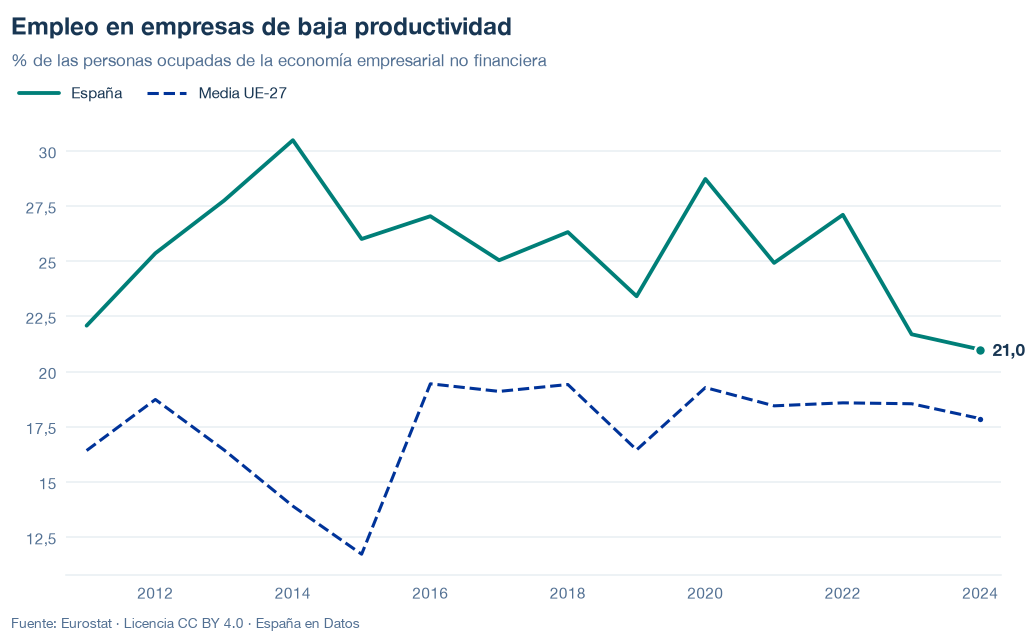

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/empleo-empresas-baja-productividad.json y data/empleo-empresas-baja-productividad.csv


## 6. Fuentes, notas y licencia

- Eurostat, estadísticas estructurales de empresas: `sbs_sc_ovw` (`LABPRY_TEUR`, `EMP_NR`) desde 2021 y `sbs_sc_ind_r2`, `sbs_sc_con_r2`, `sbs_sc_dt_r2` y `sbs_sc_1b_se_r2` (`V12150`, `V16110`) de 2008 a 2020.
- Eurostat, `prc_ppp_ind` (`PLI_EU27_2020`, `GDP`).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas explican el cálculo, la cobertura y la ruptura de serie de 2021.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.